In [1]:
from mltools.matching.render import MeshRenderer
from mltools.matching.utils import MeshroomCamerasParser
import numpy as np

data_path = "../../data/matching/meshroom"
cameras_path = f"{data_path}/cameras.sfm"
obj_path = f"{data_path}/mesh.obj"

cameras = MeshroomCamerasParser(cameras_path).parse()

# Initialize the renderer once
renderer = MeshRenderer(obj_path, default_width=1024, default_height=682)

Unique positions for visualization: 631803
Depth range for visualization: min=0.2633402943611145, max=0.4413890242576599


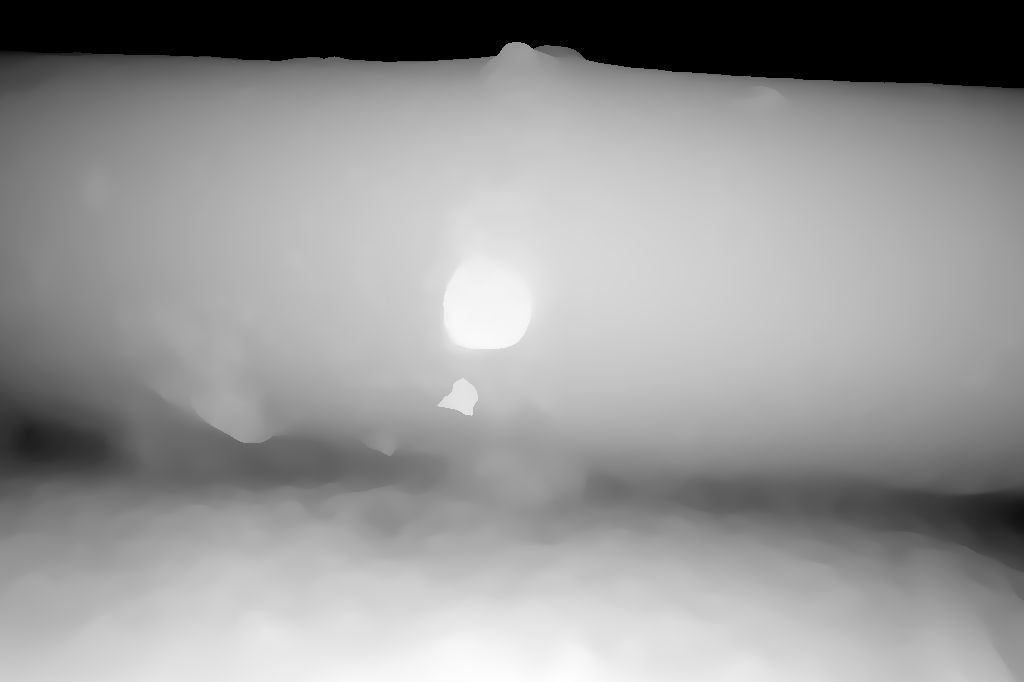

In [3]:
image_id = "2037"
camera = cameras[image_id]
image = renderer.visualize_depth(camera)  # Specify the camera position for depth visualization
display(image)

In [ ]:
pixel_data = renderer.render(camera)

In [17]:
pixel_data.shape

(682, 1024, 4)

In [38]:
data = pixel_data.reshape(-1, 4)
print(data.shape)
print(f"Unique depth values: {np.unique(data[:, 3])}")
data = data[data[:, 3] > 0.5, :3]  # Filter out invalid pixels based on alpha channel
data.shape

(698368, 4)
Unique depth values: [0. 1.]


(631803, 3)

In [33]:
np.unique(data[:, 2])

array([0.        , 0.00392157, 0.00784314, 0.01176471, 0.01568628,
       0.01960784, 0.02352941, 0.02745098, 0.03137255, 0.03529412,
       0.03921569, 0.04313726, 0.04705883, 0.0509804 , 0.05490196],
      dtype=float32)